In [25]:
from nnAudio.features.cqt import CQT
import torch
import math
from matplotlib import pyplot as plt
import numpy as np
import lightning as L
import scipy
from collections import Counter
import librosa
import torchaudio

from murenn import MuReNNDirect,DTCWT,IDTCWT


In [26]:
HYPERPARAMS = {
    "sr": 16000,
    "seg_length": 2**15,
    "win_length": 400,
    "n_mels": 8,
    "f_min": 4000,
    "f_max": 8000,
    "hop_length": 2,
    "n_samples": 5000,
}
mel_params = {
            "sample_rate": HYPERPARAMS["sr"],
            "n_fft": 1024, #512+1 bins
            "win_length": HYPERPARAMS["win_length"],
            "hop_length": HYPERPARAMS["hop_length"],
            "f_min": HYPERPARAMS["f_min"],
            "f_max": HYPERPARAMS["f_max"],
            "n_mels": HYPERPARAMS["n_mels"], #averange o
            "center": False,
            "power": 2.0
        }
col = [
    'tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple',
    'tab:brown', 'tab:pink', 'tab:gray', 'tab:olive', 'tab:cyan']
teacher = torchaudio.transforms.MelSpectrogram(**mel_params)
mel_fbank = teacher.mel_scale.fb.flip(dims=(-1,)) #nb_bins*nb_mels tensor

[]


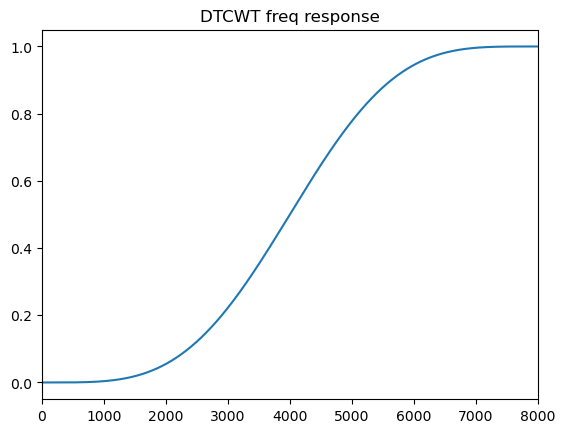

In [27]:
J_psi = int(np.ceil(np.log2(HYPERPARAMS['f_max']/HYPERPARAMS['f_min'])))
x = torch.zeros(1,1,HYPERPARAMS["sr"])
x[0,0,HYPERPARAMS["sr"]//2] = 1
dtcwt = DTCWT(J=J_psi, alternate_gh=False)
idtcwt = IDTCWT(J=J_psi, alternate_gh=False)
phi, psis = dtcwt(x)
phi = phi * 0
xj_hats = [] 
for j in range(J_psi):
    psis_j = [psis[k] if k == j else psis[k] * 0 for k in range(J_psi)]
    xj = idtcwt(phi, psis_j)
    xj_hat = torch.fft.fft(xj.squeeze()).abs()/torch.max(torch.fft.fft(xj.squeeze()).abs())
    xj_hats.append(xj_hat.detach().squeeze().numpy())  # Store the detached numpy array
    plt.plot(xj_hat.detach(), color=col[j])
plt.xlim(0, HYPERPARAMS["sr"]//2)
f_starts = []
for j in range(len(xj_hats)-1):
    diff = xj_hats[j] - xj_hats[j+1]
    f_start_j_candidates = np.where(diff > 0.01)[0]
    f_start_j = [index for index in f_start_j_candidates if xj_hats[j][index] > 0.2][0]
    f_starts.append(f_start_j)
    plt.axvline(f_start_j, color=col[j], linestyle='--')
plt.title('DTCWT freq response')
print(f_starts)

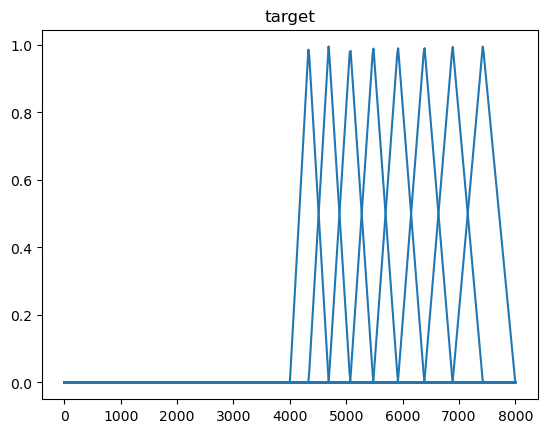

In [28]:
mel_scale = "htk"
# set x axis scale
m_min = torchaudio.functional.functional._hz_to_mel(
    teacher.f_min, mel_scale=mel_scale)
m_max = torchaudio.functional.functional._hz_to_mel(
    teacher.f_max, mel_scale=mel_scale)
# in mel scale
m_pts = torch.linspace(m_min, m_max, teacher.n_mels + 2)
# in freq(Hz) scale
f_pts = torchaudio.functional.functional._mel_to_hz(
    m_pts, mel_scale=mel_scale)
center_freqs = f_pts[1:-1]
octaves = []
for freq in center_freqs:
    octave = J_psi-1
    for j, f_start in enumerate(f_starts):
        if freq > f_start:
            octave = j
            break
    octaves.append(octave)
octaves = np.array(octaves)
Q_ctr = Counter(octaves) # filter per scale, sum = n_mels
boundaries = [0] + list(np.cumsum([Q_ctr[j] for j in range(J_psi)])) + [len(octaves)]
omega = np.linspace(0, teacher.f_max, mel_fbank.shape[0], endpoint=True)
for j in range(J_psi):
    psi_octave = mel_fbank[:, boundaries[j]:boundaries[j+2]]
    plt.plot(omega, psi_octave, color=col[j]);
plt.title('target')

HYPERPARAMS["n_octave"] = J_psi
HYPERPARAMS["octaves"] = Q_ctr

In [29]:
class SineData(torch.utils.data.Dataset):
    def __init__(self, spec):
        super().__init__()
        self.spec = spec
        self.fmax = spec["f_max"]
        self.fmin = spec["f_min"]
        self.freqs = np.logspace(
            np.log2(self.fmin),
            np.log2(self.fmax),
            spec["n_samples"],
            base=2.0,
            endpoint=False,
            dtype=np.float32
        )
        self.seg_length = spec["seg_length"]
        self.sr = spec["sr"]
        self.closure = torchaudio.transforms.MelSpectrogram(**mel_params)
    
    def __getitem__(self, idx):
        freq = self.freqs[idx]
        t = torch.arange(self.seg_length)/self.sr
        x = torch.sin(2*math.pi*freq*t)
        y = self.closure(x)
        return freq, x, y

    def __len__(self):
        return len(self.freqs)

()
torch.Size([32768])
torch.Size([8, 15873])


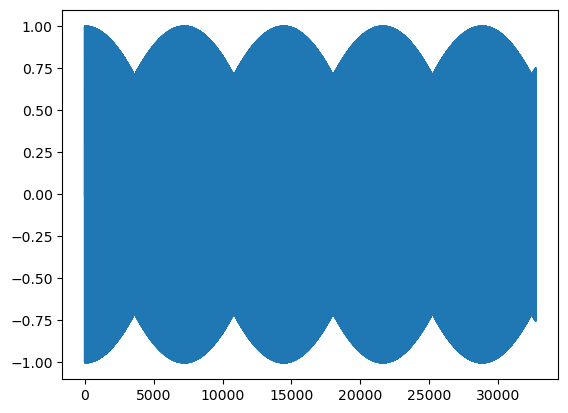

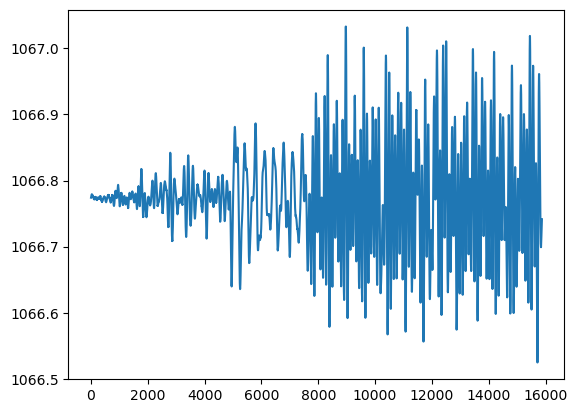

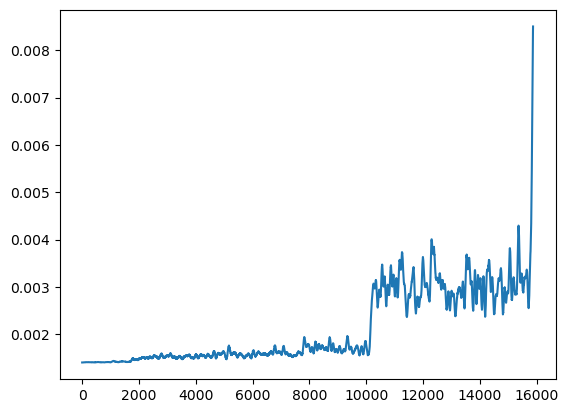

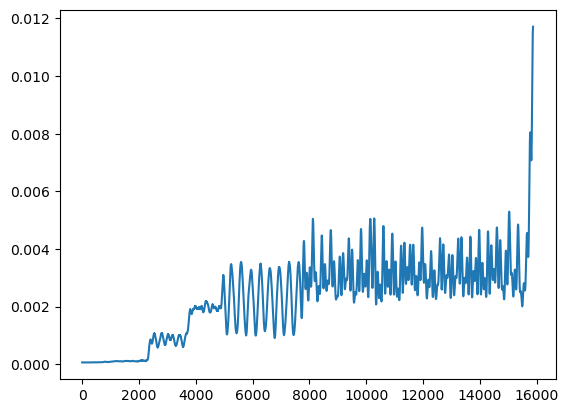

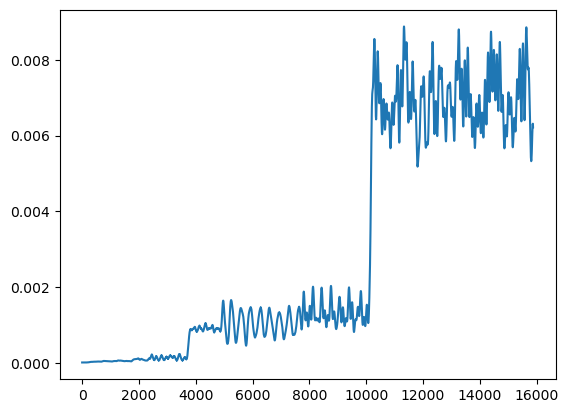

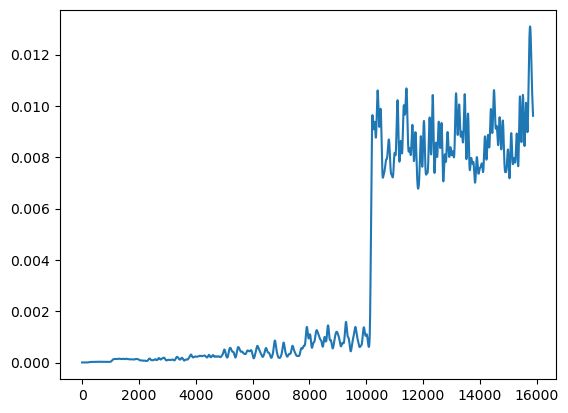

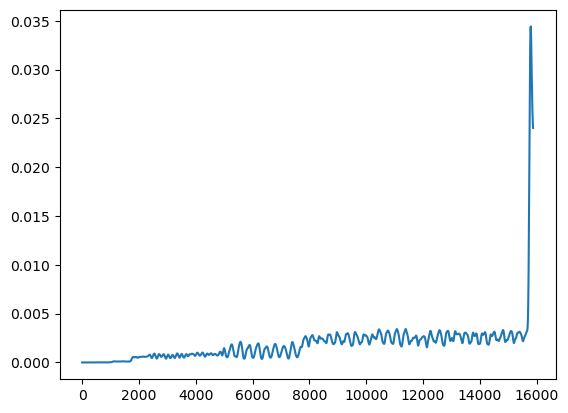

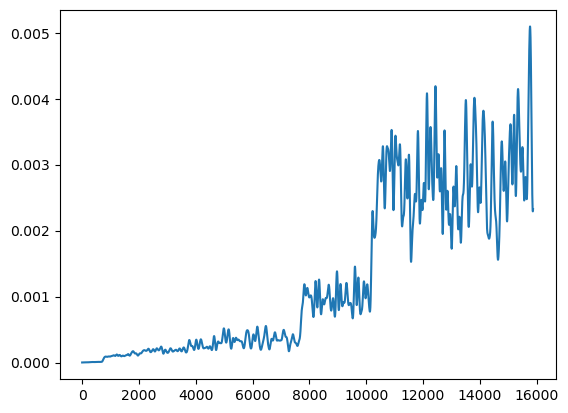

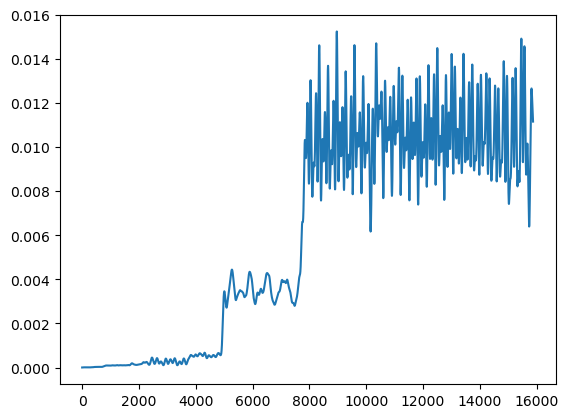

In [30]:
data = SineData(HYPERPARAMS)
for item in data[-1]:
    print(item.shape)
idx = 1
plt.plot(data[idx][1])
plt.show()
for ch in range(data[idx][2].shape[0]):
    plt.plot(data[idx][2][ch,:])
    # plt.plot(torch.fft.fft(data[idx][2][ch,:]).abs())
    plt.show()

In [31]:
class SineDataModule(L.LightningDataModule):
    def __init__(self, batch_size=32, num_workers=0):
        super().__init__()
        self.batch_size = batch_size
        self.num_workers = num_workers

    def setup(self, stage=None):
        spec = HYPERPARAMS
        dataset = SineData(spec)
        n_train = int(0.8*len(dataset))
        n_val = int(0.1*len(dataset))
        n_test = len(dataset) - n_train - n_val
        split = torch.utils.data.random_split(dataset, [n_train, n_val, n_test])
        self.train_dataset, self.val_dataset, self.test_dataset = split

    def train_dataloader(self):
        return torch.utils.data.DataLoader(
            self.train_dataset,
            batch_size=self.batch_size,
            num_workers=self.num_workers,
            shuffle=True,
        )

    def val_dataloader(self):
        return torch.utils.data.DataLoader(
            self.val_dataset,
            batch_size=self.batch_size,
            num_workers=self.num_workers,
            shuffle=False,
        )

    def test_dataloader(self):
        return torch.utils.data.DataLoader(
            self.test_dataset,
            batch_size=self.batch_size,
            num_workers=self.num_workers,
            shuffle=False,
        )

In [32]:
class Student(L.LightningModule):
    def __init__(self, spec):
        super().__init__()
        self.spec = spec
        self.train_outputs = []
        self.test_outputs = []
        self.val_outputs = []
        self.loss = torch.nn.MSELoss()
        # self.loss = torch.nn.CosineSimilarity(dim=-1)

    def step(self, batch, fold):
        feat = batch[2]
        x = batch[1]
        Sx = self.forward(x)
        n_feat = feat.shape[-1]
        n_pred = Sx.shape[-1]
        N = min(n_feat, n_pred)
        # print(feat.shape)
        # print(Sx.shape)
        # loss = criterion(outputs[:,:,:N], feat[:,:,:N])
        # loss = - self.loss(Sx[:,:, :N], feat[:,:, :N]).mean()
        loss = self.loss(Sx, feat)
        if fold == "train":
            self.train_outputs.append(loss)
        elif fold == "test":
            self.test_outputs.append(loss)
        elif fold == "val":
            self.val_outputs.append(loss)
        return {'loss': loss}

    def get_imp_fig(self, x):
        fig = plt.figure()
        conv1d = self.tfm.to_conv1d
        path_idx = 0
        paths = conv1d(x)#.flip(dims=(-2,))
        for j in range(self.J_psi):
            for q in range(self.Q[j]):
                path = paths[0, path_idx, :]
                path_hat = torch.fft.fft(path, axis=-1)
                plt.plot(torch.abs(path_hat).cpu(), color=col[j])
                path_idx +=1
        return fig

    def training_step(self, batch, batch_idx):
        return self.step(batch, "train")
    
    def validation_step(self, batch, batch_idx):
        return self.step(batch, "val")

    def test_step(self, batch, batch_idx):
        return self.step(batch, "test")
    
    def on_train_epoch_start(self):
        self.train_outputs = []
        self.test_outputs = []
        self.val_outputs = []

    def on_train_epoch_end(self):
        avg_loss = torch.tensor(self.train_outputs).mean()
        self.log('train_loss', avg_loss, prog_bar=False)
    
    def on_test_epoch_end(self):
        avg_loss = torch.tensor(self.test_outputs).mean()
        self.log('test_loss', avg_loss, prog_bar=False)

    def on_validation_epoch_end(self):
        avg_loss = torch.tensor(self.val_outputs).mean()
        x =torch.zeros(1,1,self.spec["seg_length"], device='mps')
        x[:,:,x.shape[-1]//2] = 1
        fig = self.get_imp_fig(x)
        tensorboard = self.logger.experiment
        tensorboard.add_figure("imp response", fig, global_step = self.trainer.global_step)
        tensorboard.close()
        self.log('val_loss', avg_loss, prog_bar=False)

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters())

In [33]:
class MuReNN(Student):
    def __init__(self, spec, Q_multiplier=16):
        super().__init__(spec)
        self.J_psi = spec["n_octave"]
        self.Q = spec["octaves"]
        self.tfm = MuReNNDirect(
            J = self.J_psi,
            Q = self.Q,
            T = Q_multiplier,
            in_channels = 1,
            padding_mode="zeros"
        )
        phi_kernel_size = teacher.n_fft // (2**self.J_psi) #dilation=2**J-->total kernel size = n_fft
        self.phi = torch.nn.Conv1d(
            in_channels=teacher.n_mels,
            out_channels=teacher.n_mels,
            kernel_size=phi_kernel_size ,
            stride=teacher.hop_length // (2**self.J_psi), #total stride = 2**J*(hop_length)/(2**J)=hop length
            groups=teacher.n_mels,
            bias=False)

    def forward(self, x):
        x = x.reshape(x.shape[0],1,-1)
        x_levels = self.tfm(x)
        x_levels = x_levels.reshape(x_levels.shape[0],x_levels.shape[2],-1).flip(dims=(-2,)) # B, J*Q, T
        Sx = self.phi(x_levels)
        return Sx

torch.Size([1, 1, 32768])


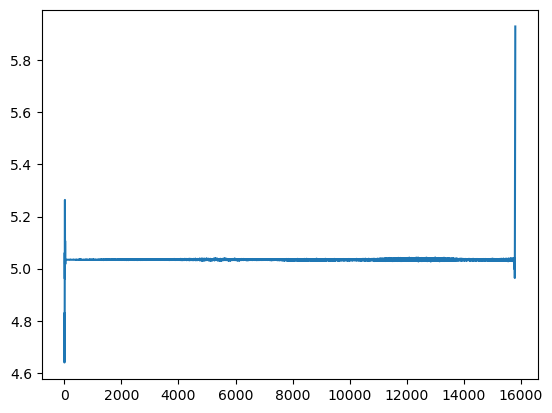

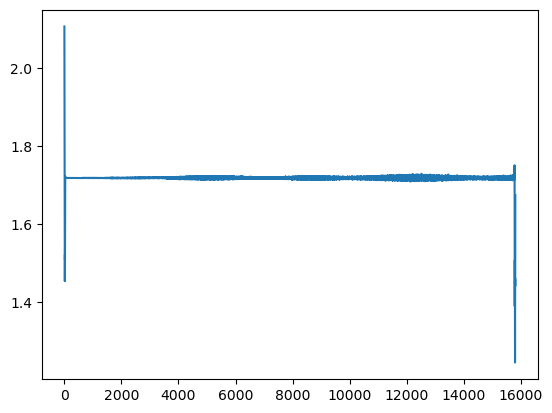

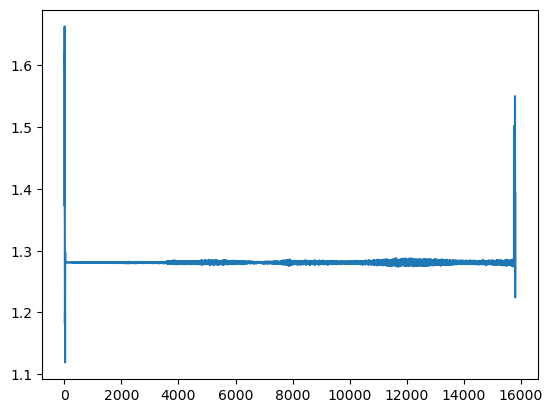

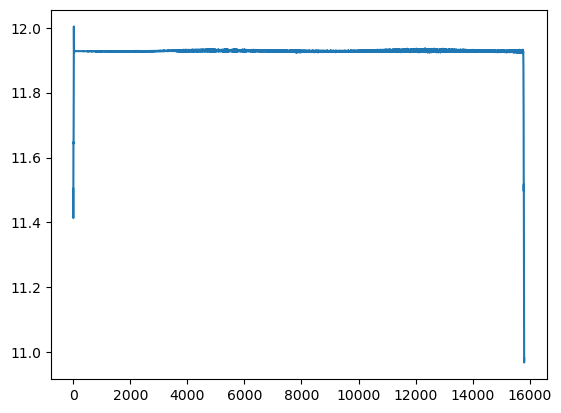

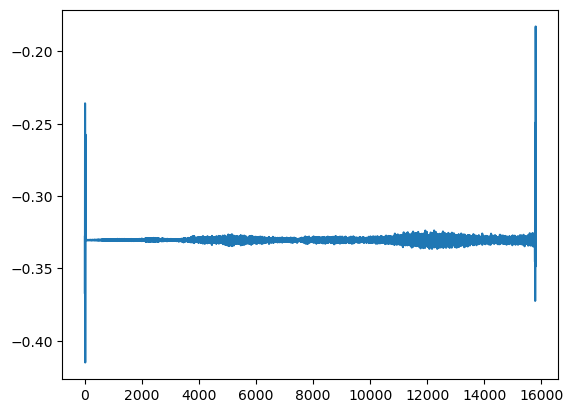

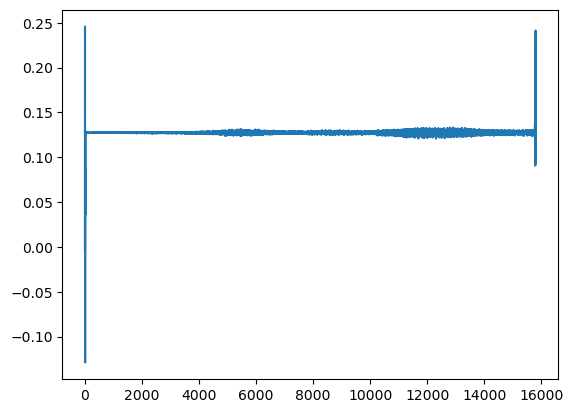

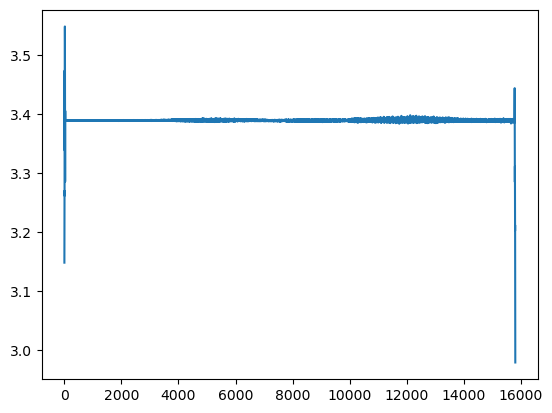

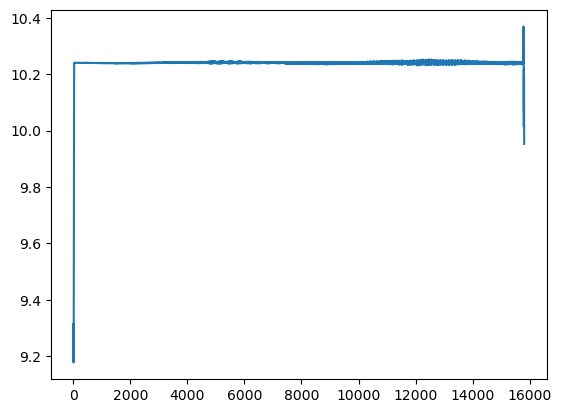

In [34]:
data = SineData(HYPERPARAMS)
murenn = MuReNN(HYPERPARAMS)
idx = 1
input = data[idx][1].reshape(1,1,-1)
print(input.shape)
Sx = murenn(input)
for ch in range(Sx.shape[1]):
    plt.plot(Sx[0,ch,:].detach()[32:-33:])
    # plt.plot(torch.fft.fft(Sx[0,ch,:].detach()).abs())
    plt.show()

In [35]:
import os
from datetime import timedelta
import datetime
import time

In [36]:
start_time = int(time.time())
sav_dir = "/Users/zhang/MuReNN/murenn_theory/reproduce_waspaa/chpt"
domain = "synth"
job_id = 0
batch_size = 10
MAX_EPOCHS = 500
model_dir = os.path.join(sav_dir, domain)
model_sav_path = os.path.join(model_dir, str(job_id))
os.makedirs(model_sav_path, exist_ok=True)

checkpoint_cb = L.pytorch.callbacks.ModelCheckpoint(
    dirpath=model_sav_path,
    monitor="val_loss",
    save_last=True,
    filename="best",
    save_weights_only=False,
)

tb_logger = L.pytorch.loggers.TensorBoardLogger(
    save_dir=os.path.join(model_sav_path, "logs")
)

if torch.cuda.is_available():
    accelerator = "gpu"
    devices = -1
    torch.multiprocessing.set_start_method("spawn")
else:
    accelerator = "cpu"
    devices = "auto"
print("Current device: ", accelerator)

dataset = SineDataModule(batch_size=batch_size, num_workers=0)
print(str(datetime.datetime.now()) + " Finished initializing dataset")


model = MuReNN(HYPERPARAMS, Q_multiplier=16)
print(str(datetime.datetime.now()) + " Finished initializing model")

trainer = L.Trainer(
    # accelerator=accelerator,
    # devices=devices,
    max_epochs=MAX_EPOCHS,
    callbacks=[checkpoint_cb],
    logger=tb_logger,
    max_time=timedelta(hours=12),
)
trainer.fit(model, dataset)

test_loss = trainer.test(model, dataset, verbose=False)
print("Model saved at: {}".format(model_sav_path))
print("Average test loss: {}".format(test_loss))
print("\n")

print(str(datetime.datetime.now()) + " Success.")
elapsed_time = time.time() - int(start_time)
elapsed_hours = int(elapsed_time / (60 * 60))
elapsed_minutes = int((elapsed_time % (60 * 60)) / 60)
elapsed_seconds = elapsed_time % 60.0
elapsed_str = "{:>02}:{:>02}:{:>05.2f}".format(
    elapsed_hours, elapsed_minutes, elapsed_seconds
)
print("Total elapsed time: " + elapsed_str + ".")

GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/Users/zhang/anaconda3/envs/murenn_fb/lib/python3.11/site-packages/lightning/pytorch/callbacks/model_checkpoint.py:652: Checkpoint directory /Users/zhang/MuReNN/murenn_theory/reproduce_waspaa/chpt/synth/0 exists and is not empty.

  | Name | Type             | Params | Mode 
--------------------------------------------------
0 | loss | CosineSimilarity | 0      | train
1 | tfm  | MuReNNDirect     | 1.0 K  | train
2 | phi  | Conv1d           | 4.1 K  | train
--------------------------------------------------
5.1 K     Trainable params
0         Non-trainable params
5.1 K     Total params
0.020     Total estimated model params size (MB)


Current device:  cpu
2024-07-10 17:02:15.961602 Finished initializing dataset
2024-07-10 17:02:15.967187 Finished initializing model
Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/Users/zhang/anaconda3/envs/murenn_fb/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:424: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


/Users/zhang/anaconda3/envs/murenn_fb/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:424: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


Epoch 9:  33%|███▎      | 131/400 [00:40<01:23,  3.21it/s, v_num=22]

/Users/zhang/anaconda3/envs/murenn_fb/lib/python3.11/site-packages/lightning/pytorch/trainer/call.py:54: Detected KeyboardInterrupt, attempting graceful shutdown...
/Users/zhang/anaconda3/envs/murenn_fb/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:424: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


Testing DataLoader 0:  98%|█████████▊| 49/50 [00:14<00:00,  3.30it/s]

(0.5, 8000.0)

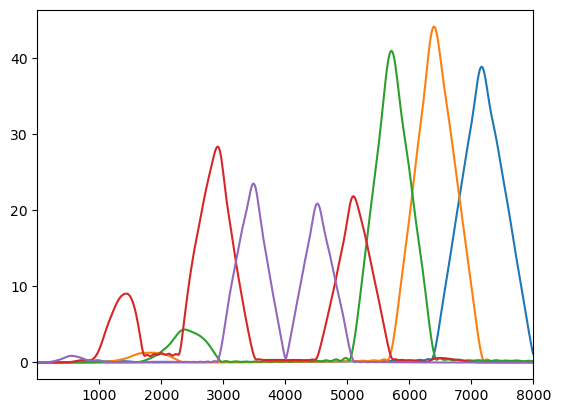

In [ ]:
ckpt_pth = "/Users/zhang/MuReNN/murenn_theory/reproduce_waspaa/chpt/synth/5/best-v9.ckpt"
M = MuReNN.load_from_checkpoint(ckpt_pth,spec=HYPERPARAMS)
M.eval()
M.to('cpu')
Q = M.tfm.Q
J = M.tfm.dtcwt.J
N = 1024
conv1d = M.tfm.to_conv1d
x = torch.zeros(1,1,N)
x[:,:,N//2] = 1
y = conv1d(x).detach().squeeze()
omega = torch.linspace(0, HYPERPARAMS['sr'], N)
path_idx = 0
for j in range(J):
    for q in range(Q[j]):
        path = y[path_idx,:]
        path_hat = torch.fft.fft(path, dim=0)
        plt.plot(omega, torch.abs(path_hat))
        path_idx += 1
plt.xlim(0.5, HYPERPARAMS['sr']//2)

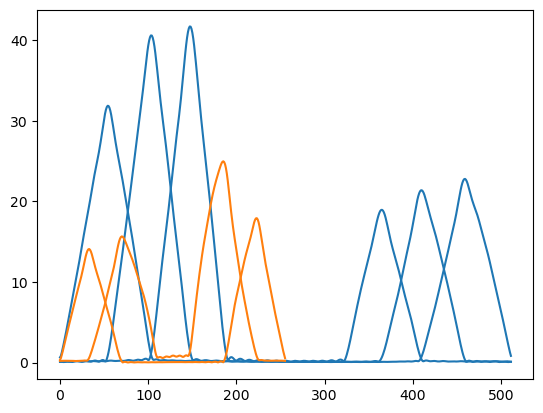

In [ ]:
ckpt_pth = "/Users/zhang/MuReNN/murenn_theory/reproduce_waspaa/chpt/synth/5/best-v9.ckpt"
M = MuReNN.load_from_checkpoint(ckpt_pth,spec=HYPERPARAMS)
M.eval()
M.to('cpu')
psis = M.tfm.conv1d
N = 1024
x = torch.zeros(1,1,N)
x[:,:,N//2] = 1
omega = torch.linspace(0, HYPERPARAMS['sr'], N)
for j, psi in enumerate(psis):
    _, xj = M.tfm.dtcwt(x)
    y = torch.complex(psi(xj[j].real), psi(xj[j].imag)).detach()
    for q in range(y.shape[1]):
        path = y[0,q,:]
        # path = scipy.signal.resample(path, N, axis=-1)
        path_hat = np.fft.fft(path)
        plt.plot(np.abs(path_hat), color=col[j])
# plt.xlim(0, N//2)